# Prolog

In [12]:
import pandas as pd
import seaborn as sb
import os
import datetime
import traceback
from scipy.optimize import curve_fit
import pathlib


def save_fig(fig, folder, name, save=True):
    """Write `fig` to <folder>/<name>.png, unless `save` is False.

    Replaces OHCParser.save_fig, which this notebook no longer imports now
    that it reads the published dataset instead of the raw spreadsheets.
    """
    if not save:
        return
    folder = pathlib.Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    fig.savefig(folder / f"{name}.png", dpi=300, bbox_inches="tight")

In [13]:
# The published dataset: one record per simulation, with the derived metrics
# (FVOPS, times and energies to solution) already in it.  Submissions are added
# to it by .github/workflows/append-submissions.yml when their pull request is
# merged -- see submissions/README.md -- so it is never edited by hand and
# never regenerated from here.
data_file = pathlib.Path("data") / "data.json"
dfs = pd.read_json(data_file)

print(f"{len(dfs)} records, {len(dfs.columns)} columns, from {data_file}")

385 records, 45 columns, from data/data.json


In [14]:
df_hardware = dfs[dfs["Track"] == "Hardware Track"]
df_software = dfs[dfs["Track"] == "Software Track"]

fig_folder = "figures_overview"
doSaveFig = False  # Set to True to save figures

# Results

In [15]:
# some statistics
print(f"""
total number of valid entries: {len(dfs)},
hardware track entries {len(df_hardware)},
software track entries {len(df_software)} ,
processesed {len(set(dfs['CPU Family']))} CPU families with {len(set(dfs['CPU Submodel']))} CPU Submodels,
-------------------
break-down by CPU Family: {df_hardware["CPU Family"].value_counts()}
-------------------
max nodes {max(dfs['Number of Nodes'])},
mmax cores {max(dfs['Number of CPU Cores'])},
min wall clc {min(dfs['Run Wall-Clock Time [s]'])},
min time step {min(dfs['Time per Iteration [s]'])},
min energy {min(dfs['Energy-To-Solution [kWh]'])} [kWh],
max energy {max(dfs['Energy-To-Solution [kWh]'])} [kWh],
decomposition methods {set(dfs["Decomposition Method"])},
renumbering methods {set(dfs["Renumbering Method"])}
network {set(dfs["Network Interconnect"])},
""")


total number of valid entries: 385,
hardware track entries 261,
software track entries 124 ,
processesed 5 CPU families with 32 CPU Submodels,
-------------------
break-down by CPU Family: CPU Family
AMD        154
Intel       60
Fujitsu     25
NVIDIA      13
ARM          9
Name: count, dtype: int64
-------------------
max nodes 512,
mmax cores 65536,
min wall clc 0.0,
min time step 0.0751141501,
min energy 0.7536666667 [kWh],
max energy 236.86656 [kWh],
decomposition methods {'hierarchical [default]', 'scotch', 'Multilevel Scotch', 'Hierarchical (16 4 2)', 'hierarquical', 'Hierarchical (6 6 4)', 'multiLevel (scotch)', 'ס', 'hierarchical', 'multiLevel scotch', 'standard', 'custom', 'Scotch', 'Hierarchical', 'N/A'},
renumbering methods {'CuthillMcKee [default]', 'CuthillMcKee', 'RCM', 'standard', 'N/A'}
network {'NVLink', 'IB FDR10 40Gb/s', 'Infiniband NDR', 'Infiniband QDR 40GBs', 'NVLink+IB', '/', 'NDR Infinibad (200 Gbit)', '200 Gbps NVIDIA Mellanox HDR InfiniBand', 'ConnectX NDR200

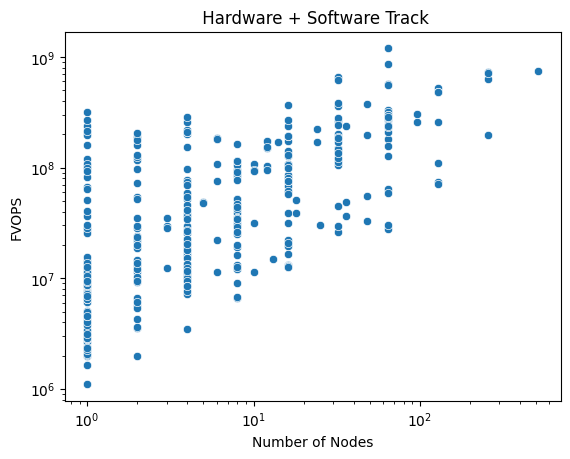

In [16]:
ax = sb.scatterplot(dfs, x="Number of Nodes", y="FVOPS")#, hue="Track")
ax.set(xscale="log", yscale="log", title=" Hardware + Software Track")
#sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
save_fig(fig, fig_folder, "FVOPSAllsubs", doSaveFig)

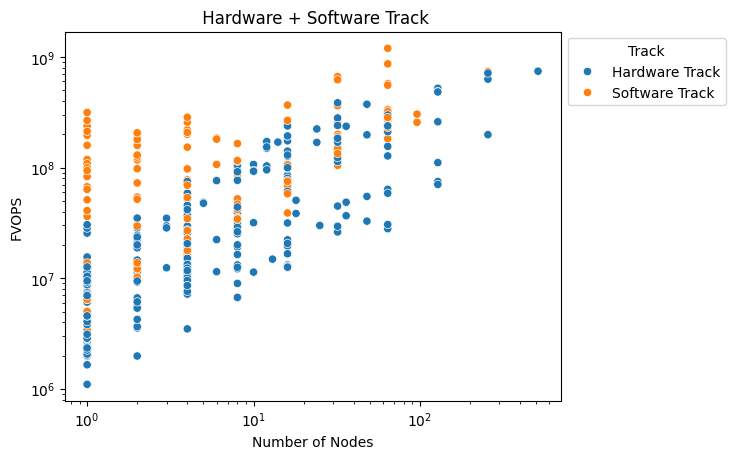

In [17]:
ax = sb.scatterplot(dfs, x="Number of Nodes", y="FVOPS", hue="Track")
ax.set(xscale="log", yscale="log", title=" Hardware + Software Track")
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
save_fig(fig, fig_folder, "FVOPSAllsubsByTrack", doSaveFig)

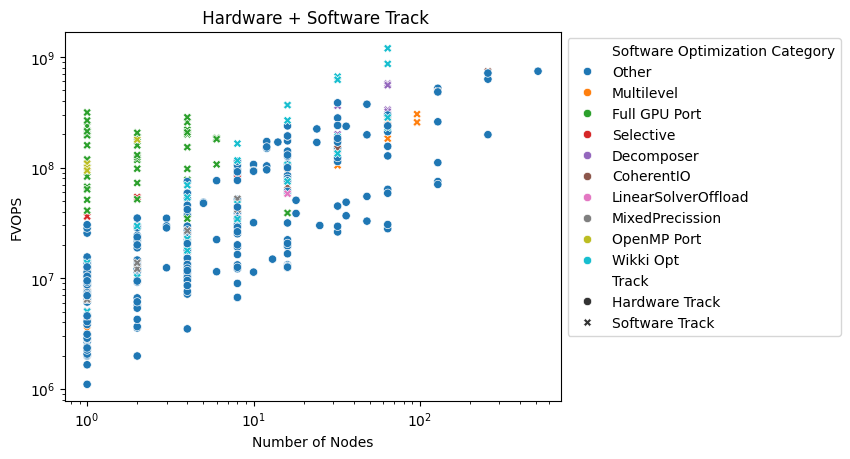

In [18]:
ax = sb.scatterplot(dfs, x="Number of Nodes", y="FVOPS", hue="Software Optimization Category", style="Track")
ax.set(xscale="log", yscale="log", title=" Hardware + Software Track")
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
save_fig(fig, fig_folder, "FVOPSAllsubsByType", doSaveFig)

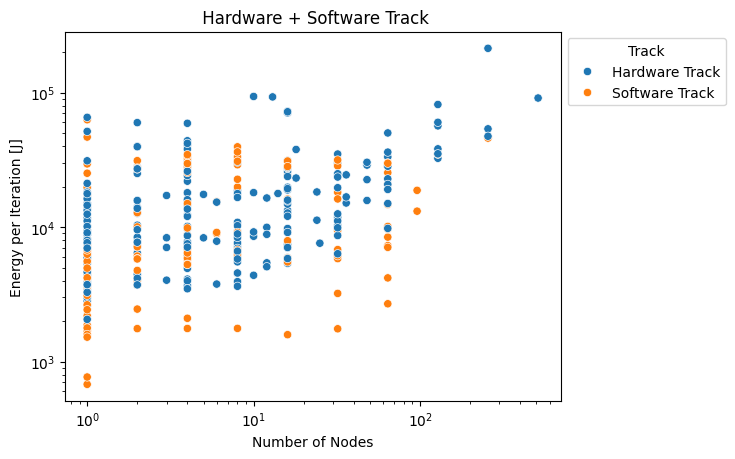

In [19]:
ax = sb.scatterplot(dfs, x="Number of Nodes", y="Energy per Iteration [J]", hue="Track")
ax.set(xscale="log", yscale="log", title=" Hardware + Software Track")
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig = ax.get_figure()
save_fig(fig, fig_folder, "FVOPSAllsubsEnergyPerIteration", doSaveFig)